# CycloneConnect: Cyclone Intensity Forecasting with ConvLSTM

This notebook documents the Deep Learning component of CycloneConnect. It prepares satellite-image patches, constructs time-ordered image sequences, and trains a ConvLSTM baseline to forecast cyclone wind intensity.

## Workflow at a glance

1. Connect to Google Drive and locate the prepared datasets.
2. Load and inspect cyclone labels and satellite patches.
3. Check image quality, missing pixels, timestamps, and data splits.
4. Prepare Channel 1 images and build four-image sequences.
5. Normalize images using training-set statistics and create train/validation/test arrays.
6. Build and train the ConvLSTM model, then save the trained model.

## Notes on running this notebook

The notebook currently uses Google Colab and files stored in Google Drive. Update the paths if your folder layout differs. The data-preparation and quality-check cells are exploratory checks, so some tables and diagnostic outputs may be lengthy. The notebook trains and saves a model; do not interpret saving the model as proof that final test-set evaluation has been completed.

## 1. Environment Setup

Connect Google Drive and confirm that the project data folder is available.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 2. Load the Prepared Datasets

Locate the extracted data, read the Parquet files, and inspect sample records.

In [ ]:
import os

folder = "/content/drive/MyDrive/cyclone"

print("Does the folder exist?", os.path.exists(folder))

if os.path.exists(folder):
    print("\nFiles inside the folder:")
    print(os.listdir(folder))

Does the folder exist? True

Files inside the folder:
['cyclone_data.tar.gz']


In [ ]:
import os
import tarfile

archive = "/content/drive/MyDrive/cyclone/cyclone_data.tar.gz"
destination = "/content/data"

os.makedirs(destination, exist_ok=True)

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(path=destination, filter="data")

print("Extraction completed!")
print("\nContents of /content/data:")
print(os.listdir(destination))

Extraction completed!

Contents of /content/data:
['patches_full', 'samples_6h']


In [ ]:
import os

for folder in ["samples_6h", "patches_full"]:
    path = f"/content/data/{folder}"

    print(f"\n{'=' * 40}")
    print(f"Folder: {folder}")
    print(f"{'=' * 40}")

    for name in os.listdir(path)[:10]:
        full_path = os.path.join(path, name)

        if os.path.isfile(full_path):
            size_mb = os.path.getsize(full_path) / (1024 * 1024)
            print(f"{name} — {size_mb:.2f} MB")
        else:
            print(f"{name}/ (subfolder)")


Folder: samples_6h
_SUCCESS — 0.00 MB
part-00000-4a0f7174-d683-4a13-bac1-233472c6f0f3-c000.snappy.parquet — 0.05 MB

Folder: patches_full
part-00886-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.06 MB
part-00001-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.03 MB
part-01073-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.05 MB
part-00023-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.12 MB
part-01053-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.16 MB
part-00098-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.02 MB
part-00853-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.08 MB
part-00128-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.06 MB
part-00655-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.03 MB
part-00811-2b286d8a-7cd9-419e-993d-1ab835ffa84d-c000.snappy.parquet — 0.17 MB


In [ ]:
import pandas as pd
import glob
import os

# Find the Parquet files
samples_files = glob.glob("/content/data/samples_6h/*.parquet")
patch_files = glob.glob("/content/data/patches_full/*.parquet")

print("Number of sample files:", len(samples_files))
print("Number of patch files:", len(patch_files))

# Read the datasets
L = pd.read_parquet("/content/data/samples_6h")
P = pd.read_parquet("/content/data/patches_full")

print("\nSamples dataset shape:", L.shape)
print("Patches dataset shape:", P.shape)

print("\nSamples columns:")
print(L.columns.tolist())

print("\nPatches columns:")
print(P.columns.tolist())

Number of sample files: 1
Number of patch files: 1155

Samples dataset shape: (4295, 8)
Patches dataset shape: (10814, 5)

Samples columns:
['SID', 'BASIN', 'ISO_TIME', 'LAT', 'LON', 'WIND_KT', 'TARGET_WIND', 'SPLIT']

Patches columns:
['SID', 'T', 'LAT', 'LON', 'PATCH']


In [ ]:
# Display the first 5 cyclone records
print("=== CYCLONE LABELS ===")
display(L.head())

# Display the first 5 satellite patch records
print("=== SATELLITE PATCHES ===")
display(P.drop(columns=["PATCH"]).head())

# Check the training, validation, and test split
print("=== DATA SPLITS ===")
print(L["SPLIT"].value_counts(dropna=False))

=== CYCLONE LABELS ===


,SID,BASIN,ISO_TIME,LAT,LON,WIND_KT,TARGET_WIND,SPLIT
0,2016138N10081,North India,2016-05-17 21:00:00,12.8,81.2,NaN,30.0,1_train
1,2016138N10081,North India,2016-05-18 00:00:00,13.1,81.2,25.0,30.0,1_train
2,2016138N10081,North India,2016-05-18 06:00:00,13.9,81.3,30.0,30.0,1_train
3,2016138N10081,North India,2016-05-18 12:00:00,14.4,81.3,30.0,30.0,1_train
4,2016138N10081,North India,2016-05-18 18:00:00,14.7,81.3,30.0,35.0,1_train


=== SATELLITE PATCHES ===


,SID,T,LAT,LON
0,2016138N10081,2016-05-17 06:00:00,10.8,81.1
1,2016138N10081,2016-05-17 09:00:00,11.2,81.1
2,2016138N10081,2016-05-17 12:00:00,11.7,81.1
3,2016138N10081,2016-05-17 21:00:00,12.8,81.2
4,2016138N10081,2016-05-17 00:00:00,10.0,80.8


=== DATA SPLITS ===
SPLIT
1_train    2806
3_test     1013
2_val       476
Name: count, dtype: int64


## 3. Understand Labels and Prediction Targets

Inspect data types, timestamps, and target wind-speed values. These checks help verify what the model is intended to predict.

In [ ]:
# STEP 7: Check data types and prediction targets

print("=== DATA TYPES ===")
print("Cyclone labels:")
print(L[["ISO_TIME", "WIND_KT", "TARGET_WIND"]].dtypes)

print("\nSatellite patches:")
print(P[["T", "PATCH"]].dtypes)

print("\n=== TARGET WIND EXAMPLES ===")
display(L[["SID", "ISO_TIME", "WIND_KT", "TARGET_WIND"]].head(15))

print("\n=== TIME DIFFERENCE BETWEEN LABELS ===")
print("Label timestamps:")
print(L["ISO_TIME"].head(10).tolist())

print("\nSatellite timestamps:")
print(P["T"].head(10).tolist())

=== DATA TYPES ===
Cyclone labels:
ISO_TIME       datetime64[ns]
WIND_KT               float64
TARGET_WIND           float64
dtype: object

Satellite patches:
T        object
PATCH    object
dtype: object

=== TARGET WIND EXAMPLES ===


,SID,ISO_TIME,WIND_KT,TARGET_WIND
0,2016138N10081,2016-05-17 21:00:00,NaN,30.0
1,2016138N10081,2016-05-18 00:00:00,25.0,30.0
2,2016138N10081,2016-05-18 06:00:00,30.0,30.0
3,2016138N10081,2016-05-18 12:00:00,30.0,30.0
4,2016138N10081,2016-05-18 18:00:00,30.0,35.0
5,2016138N10081,2016-05-18 21:00:00,NaN,35.0
6,2016138N10081,2016-05-19 00:00:00,35.0,40.0
7,2016138N10081,2016-05-19 06:00:00,40.0,40.0
8,2016138N10081,2016-05-19 09:00:00,NaN,40.0
9,2016138N10081,2016-05-19 12:00:00,40.0,40.0



=== TIME DIFFERENCE BETWEEN LABELS ===
Label timestamps:
[Timestamp('2016-05-17 21:00:00'), Timestamp('2016-05-18 00:00:00'), Timestamp('2016-05-18 06:00:00'), Timestamp('2016-05-18 12:00:00'), Timestamp('2016-05-18 18:00:00'), Timestamp('2016-05-18 21:00:00'), Timestamp('2016-05-19 00:00:00'), Timestamp('2016-05-19 06:00:00'), Timestamp('2016-05-19 09:00:00'), Timestamp('2016-05-19 12:00:00')]

Satellite timestamps:
['2016-05-17 06:00:00', '2016-05-17 09:00:00', '2016-05-17 12:00:00', '2016-05-17 21:00:00', '2016-05-17 00:00:00', '2016-05-17 03:00:00', '2016-05-17 15:00:00', '2016-05-18 00:00:00', '2016-05-18 03:00:00', '2016-05-18 12:00:00']


In [ ]:
import pandas as pd
import numpy as np

P["T"] = pd.to_datetime(P["T"], errors="coerce")

print("=== TIMESTAMP CHECK ===")
print("Label timestamp type:", L["ISO_TIME"].dtype)
print("Satellite timestamp type:", P["T"].dtype)
print("Invalid satellite timestamps:", P["T"].isna().sum())

print("\n=== PATCH DATA CHECK ===")
print("Patch data type:", type(P["PATCH"].iloc[0]))
print("Patch example type:", type(P["PATCH"].iloc[0]))
print("Patch example length:", len(P["PATCH"].iloc[0]))

print("\n=== PATCH EXAMPLE ===")
print(repr(P["PATCH"].iloc[0])[:250])


=== TIMESTAMP CHECK ===
Label timestamp type: datetime64[ns]
Satellite timestamp type: datetime64[ns]
Invalid satellite timestamps: 0

=== PATCH DATA CHECK ===
Patch data type: <class 'bytes'>
Patch example type: <class 'bytes'>
Patch example length: 16384

=== PATCH EXAMPLE ===
b"\xaaZ\x9cZ\x9cZ\xd0Z\xe7Z\xdbZ\x14[\x14['['[\x08[\x08[\xe8Z\xfeZ\xf2Z\xf2Z\x1e[\x1e[\t[\t[\xe8Z\xb8Z\xe8Z\xe8Z\xfeZ\xddZ\xe8Z\xe8Z\xfeZ\t[\t[\xac[\x05\\\x10\\\x10\\\xda[\x05\\\x02\\\x02\\\xc5[\xbd[\xbd[\xbd[\x8d[t[?[?[+[![![H[![5[5[\xbe[\x06\\\x17\


## 4. Decode and Inspect Satellite Patches

Decode the stored patch bytes and inspect image dimensions and pixel values.

In [ ]:
import numpy as np

# Get the first satellite patch
patch_bytes = P["PATCH"].iloc[0]

# Convert binary data into 16-bit floating-point numbers
patch_array = np.frombuffer(patch_bytes, dtype=np.float16)

# Display patch information
print("Original patch size in bytes:", len(patch_bytes))
print("Number of decoded values:", patch_array.size)
print("Expected values for 2 channels of 64x64:", 2 * 64 * 64)

# Display the first 10 pixel values
print("\nFirst 10 decoded values:")
print(patch_array[:10])

# Check the minimum and maximum values
print("\nMinimum value:", np.nanmin(patch_array))
print("Maximum value:", np.nanmax(patch_array))

# Count missing values
print("Number of NaN values:", np.isnan(patch_array).sum())

Original patch size in bytes: 16384
Number of decoded values: 8192
Expected values for 2 channels of 64x64: 8192

First 10 decoded values:
[213.2 211.5 211.5 218.  220.9 219.4 226.5 226.5 228.9 228.9]

Minimum value: 176.2
Maximum value: 282.8
Number of NaN values: 0


In [ ]:
# Reshape the decoded values into two 64x64 channels
patch_reshaped = patch_array.reshape(2, 64, 64)

# Rearrange the channels to the last dimension
patch_image = np.transpose(patch_reshaped, (1, 2, 0))

# Display the resulting shape
print("Reshaped patch:", patch_reshaped.shape)
print("Final image shape:", patch_image.shape)
print("Number of channels:", patch_image.shape[2])

# Check the values in each channel
for i in range(patch_image.shape[2]):
    print(f"\nChannel {i + 1}:")
    print("Minimum:", np.min(patch_image[:, :, i]))
    print("Maximum:", np.max(patch_image[:, :, i]))
    print("Mean:", np.mean(patch_image[:, :, i]))

Reshaped patch: (2, 64, 64)
Final image shape: (64, 64, 2)
Number of channels: 2

Channel 1:
Minimum: 178.5
Maximum: 282.8
Mean: 205.0

Channel 2:
Minimum: 176.2
Maximum: 236.5
Mean: 203.1


## 5. Satellite Data Quality Checks

Check patch shapes, NaN values, missing pixels, and missingness by satellite channel.

In [ ]:
# Check the size and quality of all satellite patches

print("Total satellite patches:", len(P))

# Check whether any patch has an unexpected size
patch_sizes = P["PATCH"].apply(len)

print("Patch sizes in bytes:")
print(patch_sizes.value_counts())

# Check for missing patch data
print("\nMissing patches:", P["PATCH"].isna().sum())

# Check for invalid pixel values in the decoded patches
nan_count = 0
inf_count = 0

for patch_bytes in P["PATCH"].dropna():
    values = np.frombuffer(patch_bytes, dtype=np.float16)
    nan_count += np.isnan(values).sum()
    inf_count += np.isinf(values).sum()

print("Total NaN pixel values:", nan_count)
print("Total infinite pixel values:", inf_count)

Total satellite patches: 10814
Patch sizes in bytes:
PATCH
16384    10814
Name: count, dtype: int64

Missing patches: 0
Total NaN pixel values: 5140114
Total infinite pixel values: 0


In [ ]:
# Check how many patches contain NaN values

patches_with_nan = 0
total_nan_values = 0

for patch_bytes in P["PATCH"]:
    values = np.frombuffer(patch_bytes, dtype=np.float16)

    if np.isnan(values).any():
        patches_with_nan += 1
        total_nan_values += np.isnan(values).sum()

print("Total satellite patches:", len(P))
print("Patches containing NaN values:", patches_with_nan)
print("Total NaN pixel values:", total_nan_values)
print("Patches without NaN values:", len(P) - patches_with_nan)

Total satellite patches: 10814
Patches containing NaN values: 1326
Total NaN pixel values: 5140114
Patches without NaN values: 9488


In [ ]:
# Check how many invalid pixel values occur in each patch

nan_counts = []

for patch_bytes in P["PATCH"]:
    values = np.frombuffer(patch_bytes, dtype=np.float16)
    nan_counts.append(np.isnan(values).sum())

nan_counts = np.array(nan_counts)

print("Average NaN values per patch:", nan_counts.mean())
print("Maximum NaN values in one patch:", nan_counts.max())
print("Minimum NaN values in one patch:", nan_counts.min())

print("\nNaN percentage across all pixel values:",
      (nan_counts.sum() / (len(P) * 8192)) * 100)

print("\nNaN values in the first 10 affected patches:")
print(nan_counts[nan_counts > 0][:10])

Average NaN values per patch: 475.32032550397633
Maximum NaN values in one patch: 8192
Minimum NaN values in one patch: 0

NaN percentage across all pixel values: 5.802250067187211

NaN values in the first 10 affected patches:
[  3  11 339   6   1  23  27   8 250 368]


In [ ]:
# Check missing values separately in both satellite channels

channel1_nan = 0
channel2_nan = 0
fully_invalid_patches = 0

for patch_bytes in P["PATCH"]:
    values = np.frombuffer(patch_bytes, dtype=np.float16)
    channels = values.reshape(2, 64, 64)

    # Count NaN values in each channel
    channel1_nan += np.isnan(channels[0]).sum()
    channel2_nan += np.isnan(channels[1]).sum()

    # Check whether both channels contain only NaN values
    if np.isnan(channels).all():
        fully_invalid_patches += 1

print("NaN values in channel 1:", channel1_nan)
print("NaN values in channel 2:", channel2_nan)
print("Patches with both channels entirely missing:", fully_invalid_patches)

NaN values in channel 1: 12288
NaN values in channel 2: 5127826
Patches with both channels entirely missing: 3


In [ ]:
# Calculate the percentage of missing values in each channel

total_pixels_per_channel = len(P) * 64 * 64

channel1_valid = total_pixels_per_channel - channel1_nan
channel2_valid = total_pixels_per_channel - channel2_nan

print("=== CHANNEL 1 ===")
print("Valid pixel values:", channel1_valid)
print("Missing pixel percentage:", round(channel1_nan / total_pixels_per_channel * 100, 2), "%")

print("\n=== CHANNEL 2 ===")
print("Valid pixel values:", channel2_valid)
print("Missing pixel percentage:", round(channel2_nan / total_pixels_per_channel * 100, 2), "%")

# Inspect valid values in each channel
channel1_values = []
channel2_values = []

for patch_bytes in P["PATCH"]:
    channels = np.frombuffer(patch_bytes, dtype=np.float16).reshape(2, 64, 64)

    channel1_values.extend(channels[0][np.isfinite(channels[0])])
    channel2_values.extend(channels[1][np.isfinite(channels[1])])

print("\n=== VALID PIXEL VALUE RANGES ===")
print("Channel 1 minimum:", np.min(channel1_values))
print("Channel 1 maximum:", np.max(channel1_values))

print("Channel 2 minimum:", np.min(channel2_values))
print("Channel 2 maximum:", np.max(channel2_values))

=== CHANNEL 1 ===
Valid pixel values: 44281856
Missing pixel percentage: 0.03 %

=== CHANNEL 2 ===
Valid pixel values: 39166318
Missing pixel percentage: 11.58 %

=== VALID PIXEL VALUE RANGES ===
Channel 1 minimum: 169.6
Channel 1 maximum: 321.8
Channel 2 minimum: 130.2
Channel 2 maximum: 284.8


## 6. Check Wind Labels, Timestamp Matching, and Splits

Inspect missing wind-speed labels, target timing, timestamp alignment, and dataset split assignments.

In [ ]:
# Check missing values and distribution of wind speed labels

print("Missing current wind speeds:", L["WIND_KT"].isna().sum())
print("Missing target wind speeds:", L["TARGET_WIND"].isna().sum())

print("\nTarget wind speed statistics:")
print(L["TARGET_WIND"].describe())

print("\nUnique data splits:")
print(L["SPLIT"].value_counts())

print("\nExample wind speed values:")
display(L[["SID", "ISO_TIME", "WIND_KT", "TARGET_WIND", "SPLIT"]].head(20))

Missing current wind speeds: 244
Missing target wind speeds: 0

Target wind speed statistics:
count    4295.000000
mean       48.844005
std        24.568420
min        15.000000
25%        30.000000
50%        40.000000
75%        60.000000
max       165.000000
Name: TARGET_WIND, dtype: float64

Unique data splits:
SPLIT
1_train    2806
3_test     1013
2_val       476
Name: count, dtype: int64

Example wind speed values:


,SID,ISO_TIME,WIND_KT,TARGET_WIND,SPLIT
0,2016138N10081,2016-05-17 21:00:00,NaN,30.0,1_train
1,2016138N10081,2016-05-18 00:00:00,25.0,30.0,1_train
2,2016138N10081,2016-05-18 06:00:00,30.0,30.0,1_train
3,2016138N10081,2016-05-18 12:00:00,30.0,30.0,1_train
4,2016138N10081,2016-05-18 18:00:00,30.0,35.0,1_train
5,2016138N10081,2016-05-18 21:00:00,NaN,35.0,1_train
6,2016138N10081,2016-05-19 00:00:00,35.0,40.0,1_train
7,2016138N10081,2016-05-19 06:00:00,40.0,40.0,1_train
8,2016138N10081,2016-05-19 09:00:00,NaN,40.0,1_train
9,2016138N10081,2016-05-19 12:00:00,40.0,40.0,1_train


In [ ]:
# Compare TARGET_WIND with future observed wind speeds
# This helps us identify the prediction time horizon.

L_check = L.drop_duplicates(["SID", "ISO_TIME"]).copy()

# Create a lookup of observed wind speeds by cyclone and timestamp
wind_lookup = L_check.set_index(["SID", "ISO_TIME"])["WIND_KT"]

for hours in [3, 6, 9, 12, 24]:

    # Find the timestamp that many hours into the future
    future_times = L_check["ISO_TIME"] + pd.Timedelta(hours=hours)

    # Look up the observed wind speed at those future timestamps
    future_keys = pd.MultiIndex.from_arrays([
        L_check["SID"],
        future_times
    ])

    future_wind = wind_lookup.reindex(future_keys).to_numpy()

    # Compare future observed wind speed with TARGET_WIND
    valid = ~np.isnan(future_wind)

    if valid.sum() > 0:
        matches = (
            future_wind[valid]
            == L_check["TARGET_WIND"].to_numpy()[valid]
        )

        print(
            f"+{hours} hours: "
            f"{valid.sum()} matching timestamps, "
            f"{matches.mean() * 100:.2f}% exact target matches"
        )
    else:
        print(f"+{hours} hours: No matching timestamps found")

+3 hours: 1558 matching timestamps, 60.46% exact target matches
+6 hours: 3758 matching timestamps, 100.00% exact target matches
+9 hours: 1503 matching timestamps, 60.94% exact target matches
+12 hours: 3386 matching timestamps, 48.73% exact target matches
+24 hours: 2745 matching timestamps, 22.26% exact target matches


In [ ]:
# Check whether satellite patches match label timestamps

label_keys = set(zip(L["SID"], L["ISO_TIME"]))
patch_keys = set(zip(P["SID"], P["T"]))

matched = label_keys & patch_keys

print("=== SATELLITE PATCH ALIGNMENT ===")
print("Total label rows:", len(L))
print("Total satellite patches:", len(P))
print("Unique label cyclone-timestamps:", len(label_keys))
print("Unique patch cyclone-timestamps:", len(patch_keys))
print("Matching cyclone-timestamps:", len(matched))
print("Label timestamps with matching patches:",
      f"{len(matched) / len(label_keys) * 100:.2f}%")

print("\nExample matching timestamps:")
for sid, timestamp in list(matched)[:5]:
    print(sid, timestamp)

=== SATELLITE PATCH ALIGNMENT ===
Total label rows: 4295
Total satellite patches: 10814
Unique label cyclone-timestamps: 4295
Unique patch cyclone-timestamps: 10814
Matching cyclone-timestamps: 4292
Label timestamps with matching patches: 99.93%

Example matching timestamps:
2022080S09087 2022-03-22 00:00:00
2025261N23166 2025-09-26 12:00:00
2025290S05081 2025-10-24 06:00:00
2020279N11256 2020-10-13 00:00:00
2024145N14087 2024-05-25 06:00:00


In [ ]:
# Inspect the dataset splits

print("=== LABEL SPLITS ===")
print(L["SPLIT"].value_counts().sort_index())

print("\n=== UNIQUE CYCLONES PER SPLIT ===")
for split_name, group in L.groupby("SPLIT"):
    print(
        f"{split_name}: "
        f"{group['SID'].nunique()} unique cyclones, "
        f"{len(group)} samples"
    )

print("\n=== CYCLONES APPEARING IN MULTIPLE SPLITS ===")
split_counts = L.groupby("SID")["SPLIT"].nunique()
shared_cyclones = split_counts[split_counts > 1]

print("Cyclones appearing in multiple splits:", len(shared_cyclones))
print("Examples:", shared_cyclones.index.tolist()[:10])

=== LABEL SPLITS ===
SPLIT
1_train    2806
2_val       476
3_test     1013
Name: count, dtype: int64

=== UNIQUE CYCLONES PER SPLIT ===
1_train: 212 unique cyclones, 2806 samples
2_val: 24 unique cyclones, 476 samples
3_test: 75 unique cyclones, 1013 samples

=== CYCLONES APPEARING IN MULTIPLE SPLITS ===
Cyclones appearing in multiple splits: 0
Examples: []


## 7. Investigate Missing Images and Temporal Consistency

Identify fully missing patches, check timestamp gaps and duplicates, and examine how patches align with the label splits.

In [ ]:
import numpy as np

# Inspect missing pixel values in the satellite patches

total_patches = len(P)
total_pixels = 0
patches_with_nan = 0
fully_missing_patches = 0

for patch_bytes in P["PATCH"]:
    patch = np.frombuffer(patch_bytes, dtype=np.float16)

    total_pixels += patch.size
    nan_count = np.isnan(patch).sum()

    if nan_count > 0:
        patches_with_nan += 1

    if nan_count == patch.size:
        fully_missing_patches += 1

print("=== SATELLITE PATCH QUALITY ===")
print("Total patches:", total_patches)
print("Pixels per patch:", 8192)
print("Total pixel values:", total_pixels)
print("Patches containing NaNs:", patches_with_nan)
print("Completely missing patches:", fully_missing_patches)
print(
    "Percentage of patches containing NaNs:",
    f"{patches_with_nan / total_patches * 100:.2f}%"
)

=== SATELLITE PATCH QUALITY ===
Total patches: 10814
Pixels per patch: 8192
Total pixel values: 88588288
Patches containing NaNs: 1326
Completely missing patches: 3
Percentage of patches containing NaNs: 12.26%


In [ ]:
import numpy as np

# Identify satellite patches where every pixel is NaN

fully_missing = []

for idx, row in P.iterrows():
    patch = np.frombuffer(row["PATCH"], dtype=np.float16)

    if np.isnan(patch).all():
        fully_missing.append({
            "row_index": idx,
            "SID": row["SID"],
            "T": row["T"],
            "LAT": row["LAT"],
            "LON": row["LON"]
        })

fully_missing_df = pd.DataFrame(fully_missing)

print("=== COMPLETELY MISSING SATELLITE PATCHES ===")
print(fully_missing_df.to_string(index=False))

=== COMPLETELY MISSING SATELLITE PATCHES ===
 row_index           SID                   T  LAT   LON
      3650 2020154N19269 2020-06-04 00:00:00 18.2 -91.7
      5653 2020154N19269 2020-06-03 18:00:00 18.5 -91.9
      5654 2020154N19269 2020-06-03 21:00:00 18.4 -91.8


In [ ]:
# Check whether the completely missing patches match cyclone labels

missing_keys = set(
    zip(fully_missing_df["SID"], fully_missing_df["T"])
)

missing_labels = L[
    L.apply(lambda row: (row["SID"], row["ISO_TIME"]) in missing_keys, axis=1)
][["SID", "ISO_TIME", "WIND_KT", "TARGET_WIND", "SPLIT"]]

print("=== LABELS FOR COMPLETELY MISSING PATCHES ===")

if missing_labels.empty:
    print("No matching labels found.")
else:
    print(missing_labels.to_string(index=False))

=== LABELS FOR COMPLETELY MISSING PATCHES ===
          SID            ISO_TIME  WIND_KT  TARGET_WIND   SPLIT
2020154N19269 2020-06-03 18:00:00     45.0         40.0 1_train
2020154N19269 2020-06-04 00:00:00     40.0         35.0 1_train


In [ ]:
# Check the time intervals between satellite patches

P_sorted = P.sort_values(["SID", "T"]).copy()

# Calculate the time difference between consecutive patches
P_sorted["TIME_GAP_HOURS"] = (
    P_sorted.groupby("SID")["T"]
    .diff()
    .dt.total_seconds() / 3600
)

print("=== SATELLITE PATCH TIME INTERVALS ===")

print("\nTime gap distribution (hours):")
print(
    P_sorted["TIME_GAP_HOURS"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\n=== COMMON TIME INTERVALS ===")

print(
    P_sorted["TIME_GAP_HOURS"]
    .dropna()
    .round(2)
    .value_counts()
    .head(10)
)

print("\n=== PATCHES PER CYCLONE ===")

patch_counts = P.groupby("SID").size()

print(patch_counts.describe())

print("\nNumber of unique cyclones with satellite patches:",
      P["SID"].nunique())

print("\n=== FIRST 10 PATCHES FOR ONE CYCLONE ===")

example_sid = P_sorted["SID"].iloc[0]

print(
    P_sorted[P_sorted["SID"] == example_sid][
        ["SID", "T", "LAT", "LON", "TIME_GAP_HOURS"]
    ].head(10).to_string(index=False)
)

=== SATELLITE PATCH TIME INTERVALS ===

Time gap distribution (hours):
TIME_GAP_HOURS
3.0      10471
6.0          4
9.0          2
21.0         5
24.0         4
45.0         4
51.0         1
54.0         2
57.0         2
66.0         2
90.0         1
144.0        1
147.0        2
159.0        1
300.0        1
Name: count, dtype: int64

=== COMMON TIME INTERVALS ===
TIME_GAP_HOURS
3.0      10471
21.0         5
45.0         4
24.0         4
6.0          4
66.0         2
9.0          2
57.0         2
147.0        2
54.0         2
Name: count, dtype: int64

=== PATCHES PER CYCLONE ===
count    311.000000
mean      34.771704
std       21.137247
min       10.000000
25%       18.000000
50%       30.000000
75%       45.000000
max      113.000000
dtype: float64

Number of unique cyclones with satellite patches: 311

=== FIRST 10 PATCHES FOR ONE CYCLONE ===
          SID                   T  LAT  LON  TIME_GAP_HOURS
2016138N10081 2016-05-17 00:00:00 10.0 80.8             NaN
2016138N10081 2016-0

In [ ]:
# Check for duplicate cyclone-timestamp pairs

duplicate_mask = P.duplicated(
    subset=["SID", "T"],
    keep=False
)

duplicates = P.loc[duplicate_mask].sort_values(
    ["SID", "T"]
)

print("=== DUPLICATE SATELLITE PATCH CHECK ===")

print("Total satellite patches:", len(P))

print(
    "Duplicate cyclone-timestamp rows:",
    int(duplicate_mask.sum())
)

print(
    "Unique duplicated cyclone-timestamp pairs:",
    duplicates[["SID", "T"]].drop_duplicates().shape[0]
)

if not duplicates.empty:
    print("\nExample duplicates:")
    print(
        duplicates[["SID", "T", "LAT", "LON"]]
        .head(20)
        .to_string(index=False)
    )
else:
    print("\nNo duplicate cyclone-timestamp pairs found.")

=== DUPLICATE SATELLITE PATCH CHECK ===
Total satellite patches: 10814
Duplicate cyclone-timestamp rows: 0
Unique duplicated cyclone-timestamp pairs: 0

No duplicate cyclone-timestamp pairs found.


In [ ]:
# Check satellite patch alignment with the label dataset splits

# Create a lookup of cyclone-timestamp pairs and their data split
label_split_lookup = L[
    ["SID", "ISO_TIME", "SPLIT"]
].copy()

# Match satellite patches to labels using cyclone ID and timestamp
P_check = P.merge(
    label_split_lookup,
    left_on=["SID", "T"],
    right_on=["SID", "ISO_TIME"],
    how="left",
    validate="one_to_one"
)

print("=== SATELLITE PATCH SPLIT ALIGNMENT ===")

print("Total satellite patches:", len(P_check))

print("\nPatch split counts:")
print(P_check["SPLIT"].value_counts(dropna=False))

print(
    "\nPatches matching a label:",
    P_check["SPLIT"].notna().sum()
)

print(
    "Patches without a matching label:",
    P_check["SPLIT"].isna().sum()
)

print("\n=== MATCHING LABELS BY SPLIT ===")
print(
    P_check.groupby("SPLIT", dropna=False)
    .size()
)

=== SATELLITE PATCH SPLIT ALIGNMENT ===
Total satellite patches: 10814

Patch split counts:
SPLIT
NaN        6522
1_train    2803
3_test     1013
2_val       476
Name: count, dtype: int64

Patches matching a label: 4292
Patches without a matching label: 6522

=== MATCHING LABELS BY SPLIT ===
SPLIT
1_train    2803
2_val       476
3_test     1013
NaN        6522
dtype: int64


In [ ]:
# Check which data split each cyclone belongs to

# Create a mapping from each cyclone ID to its split
cyclone_split_lookup = (
    L[["SID", "SPLIT"]]
    .drop_duplicates()
)

# Check whether any cyclone appears in multiple splits
split_counts = cyclone_split_lookup.groupby("SID")["SPLIT"].nunique()

print("=== CYCLONE SPLIT CONSISTENCY ===")
print("Total unique cyclones:", cyclone_split_lookup["SID"].nunique())
print("Cyclones assigned to multiple splits:", (split_counts > 1).sum())

# Assign each satellite patch its cyclone's split
P_split = P.merge(
    cyclone_split_lookup,
    on="SID",
    how="left",
    validate="many_to_one"
)

print("\n=== ALL SATELLITE PATCHES BY CYCLONE SPLIT ===")
print(P_split["SPLIT"].value_counts(dropna=False))

print("\n=== PATCHES PER SPLIT ===")
print(
    P_split.groupby("SPLIT", dropna=False)["SID"]
    .count()
)

print("\n=== PATCHES WITH UNKNOWN CYCLONE SPLIT ===")
print(P_split["SPLIT"].isna().sum())

=== CYCLONE SPLIT CONSISTENCY ===
Total unique cyclones: 311
Cyclones assigned to multiple splits: 0

=== ALL SATELLITE PATCHES BY CYCLONE SPLIT ===
SPLIT
1_train    7174
3_test     2691
2_val       949
Name: count, dtype: int64

=== PATCHES PER SPLIT ===
SPLIT
1_train    7174
2_val       949
3_test     2691
Name: SID, dtype: int64

=== PATCHES WITH UNKNOWN CYCLONE SPLIT ===
0


In [ ]:
# Check missing values in satellite patches by data split

print("=== CHECKING MISSING SATELLITE IMAGE VALUES ===")

missing_patch_counts = {
    "1_train": 0,
    "2_val": 0,
    "3_test": 0
}

fully_missing_counts = {
    "1_train": 0,
    "2_val": 0,
    "3_test": 0
}

total_nan_values = {
    "1_train": 0,
    "2_val": 0,
    "3_test": 0
}

for split in ["1_train", "2_val", "3_test"]:
    split_patches = P_split.loc[
        P_split["SPLIT"] == split, "PATCH"
    ]

    for patch_bytes in split_patches:
        image = np.frombuffer(
            patch_bytes, dtype=np.float16
        )

        nan_count = np.isnan(image).sum()

        if nan_count > 0:
            missing_patch_counts[split] += 1

        if nan_count == len(image):
            fully_missing_counts[split] += 1

        total_nan_values[split] += nan_count

results = pd.DataFrame({
    "Split": list(missing_patch_counts.keys()),
    "Total patches": [
        int((P_split["SPLIT"] == split).sum())
        for split in missing_patch_counts
    ],
    "Patches with missing pixels": [
        missing_patch_counts[split]
        for split in missing_patch_counts
    ],
    "Completely missing patches": [
        fully_missing_counts[split]
        for split in fully_missing_counts
    ],
    "Total NaN pixel values": [
        total_nan_values[split]
        for split in total_nan_values
    ]
})

print(results.to_string(index=False))

=== CHECKING MISSING SATELLITE IMAGE VALUES ===
  Split  Total patches  Patches with missing pixels  Completely missing patches  Total NaN pixel values
1_train           7174                          101                           3                  165810
  2_val            949                          278                           0                 1134593
 3_test           2691                          947                           0                 3839711


In [ ]:
# Identify completely missing satellite patches

fully_missing_rows = []

for idx, row in P_split.iterrows():
    image = np.frombuffer(row["PATCH"], dtype=np.float16)

    if np.isnan(image).all():
        fully_missing_rows.append({
            "SID": row["SID"],
            "Timestamp": row["T"],
            "Latitude": row["LAT"],
            "Longitude": row["LON"],
            "Split": row["SPLIT"]
        })

fully_missing_df = pd.DataFrame(fully_missing_rows)

print("=== COMPLETELY MISSING SATELLITE PATCHES ===")
print("Number of completely missing patches:", len(fully_missing_df))

if len(fully_missing_df) > 0:
    print(fully_missing_df.to_string(index=False))
else:
    print("No completely missing patches found.")

=== COMPLETELY MISSING SATELLITE PATCHES ===
Number of completely missing patches: 3
          SID           Timestamp  Latitude  Longitude   Split
2020154N19269 2020-06-04 00:00:00      18.2      -91.7 1_train
2020154N19269 2020-06-03 18:00:00      18.5      -91.9 1_train
2020154N19269 2020-06-03 21:00:00      18.4      -91.8 1_train


## 8. Visual and Channel-Availability Analysis

Visualize sample satellite images and summarize missingness across data splits, years, and channels.

=== SAMPLE SATELLITE IMAGE ===
Cyclone ID: 2016138N10081
Timestamp: 2016-05-17 06:00:00
Split: 1_train
Image shape: (64, 64, 2)

Channel 1:
Valid pixels: 4096
Missing pixels: 0
Minimum: 178.5
Maximum: 282.75
Mean: 205.0

Channel 2:
Valid pixels: 4096
Missing pixels: 0
Minimum: 176.25
Maximum: 236.5
Mean: 203.125


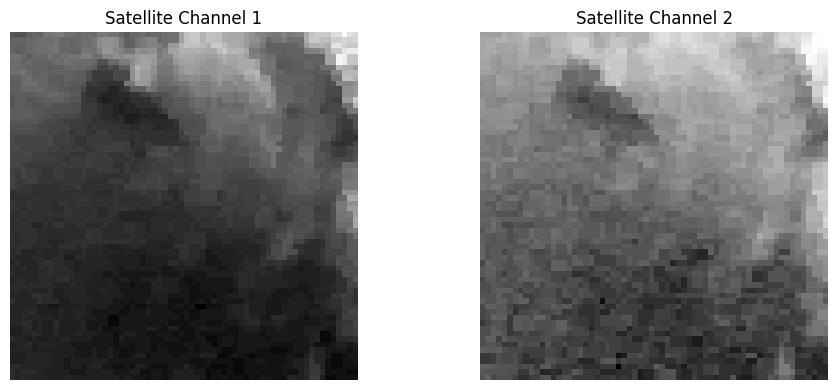

In [ ]:
# Decode and inspect one satellite image

import numpy as np
import matplotlib.pyplot as plt

# Select the first satellite patch that contains some valid pixels
sample_row = None

for _, row in P_split.iterrows():
    patch_array = np.frombuffer(
        row["PATCH"], dtype=np.float16
    )

    if not np.isnan(patch_array).all():
        sample_row = row
        break

# Decode the patch into two 64x64 channels
image = np.frombuffer(
    sample_row["PATCH"], dtype=np.float16
).reshape(2, 64, 64).transpose(1, 2, 0)

print("=== SAMPLE SATELLITE IMAGE ===")
print("Cyclone ID:", sample_row["SID"])
print("Timestamp:", sample_row["T"])
print("Split:", sample_row["SPLIT"])
print("Image shape:", image.shape)

for channel in range(image.shape[2]):
    valid_pixels = image[:, :, channel]
    valid_pixels = valid_pixels[np.isfinite(valid_pixels)]

    print(f"\nChannel {channel + 1}:")
    print("Valid pixels:", len(valid_pixels))
    print("Missing pixels:", np.isnan(image[:, :, channel]).sum())

    if len(valid_pixels) > 0:
        print("Minimum:", float(valid_pixels.min()))
        print("Maximum:", float(valid_pixels.max()))
        print("Mean:", float(valid_pixels.mean()))

# Display both channels
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for channel in range(2):
    axes[channel].imshow(image[:, :, channel], cmap="gray")
    axes[channel].set_title(f"Satellite Channel {channel + 1}")
    axes[channel].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Analyze missing values across all satellite patches
results = []

for split in ["1_train", "2_val", "3_test"]:
    split_data = P_split[P_split["SPLIT"] == split]

    valid_images = 0
    partially_missing_images = 0
    fully_missing_images = 0
    channel_nan_counts = np.zeros(2, dtype=np.int64)

    for patch_bytes in split_data["PATCH"]:
        image = np.frombuffer(
            patch_bytes, dtype=np.float16
        ).reshape(2, 64, 64)

        missing = np.isnan(image)
        total_missing = missing.sum()

        channel_nan_counts += missing.sum(axis=(1, 2))

        if total_missing == 0:
            valid_images += 1
        elif total_missing == image.size:
            fully_missing_images += 1
        else:
            partially_missing_images += 1

    total_images = len(split_data)
    pixels_per_channel = total_images * 64 * 64

    results.append({
        "Split": split,
        "Total images": total_images,
        "Fully valid images": valid_images,
        "Partially missing images": partially_missing_images,
        "Completely missing images": fully_missing_images,
        "Channel 1 missing (%)": round(
            100 * channel_nan_counts[0] / pixels_per_channel, 3
        ),
        "Channel 2 missing (%)": round(
            100 * channel_nan_counts[1] / pixels_per_channel, 3
        )
    })

results_df = pd.DataFrame(results)

print("=== SATELLITE IMAGE QUALITY REPORT ===")
print(results_df.to_string(index=False))

=== SATELLITE IMAGE QUALITY REPORT ===
  Split  Total images  Fully valid images  Partially missing images  Completely missing images  Channel 1 missing (%)  Channel 2 missing (%)
1_train          7174                7073                        98                          3                  0.042                  0.522
  2_val           949                 671                       278                          0                  0.000                 29.189
 3_test          2691                1744                       947                          0                  0.000                 34.836


In [ ]:
# Find satellite images with the highest percentage of missing pixels

missing_report = []

for _, row in P_split.iterrows():
    values = np.frombuffer(
        row["PATCH"], dtype=np.float16
    ).reshape(2, 64, 64)

    channel2_missing = np.isnan(values[1]).sum()
    total_pixels = values[1].size

    missing_report.append({
        "SID": row["SID"],
        "Timestamp": row["T"],
        "Split": row["SPLIT"],
        "Channel 1 missing (%)": round(
            100 * np.isnan(values[0]).mean(), 2
        ),
        "Channel 2 missing (%)": round(
            100 * channel2_missing / total_pixels, 2
        )
    })

missing_report = pd.DataFrame(missing_report)

print("=== IMAGES WITH THE MOST MISSING CHANNEL 2 PIXELS ===")

print(
    missing_report.sort_values(
        "Channel 2 missing (%)", ascending=False
    ).head(10).to_string(index=False)
)

print("\n=== AVERAGE CHANNEL 2 MISSINGNESS BY SPLIT ===")

print(
    missing_report.groupby("Split")["Channel 2 missing (%)"]
    .mean()
    .round(2)
)

=== IMAGES WITH THE MOST MISSING CHANNEL 2 PIXELS ===
          SID           Timestamp  Split  Channel 1 missing (%)  Channel 2 missing (%)
2024328S09096 2024-11-27 12:00:00 3_test                    0.0                  100.0
2024328S09096 2024-11-27 15:00:00 3_test                    0.0                  100.0
2024329N04089 2024-11-27 15:00:00 3_test                    0.0                  100.0
2024329N04089 2024-11-27 18:00:00 3_test                    0.0                  100.0
2024328S09096 2024-11-27 18:00:00 3_test                    0.0                  100.0
2024328S09096 2024-11-28 03:00:00 3_test                    0.0                  100.0
2024329N04089 2024-11-28 03:00:00 3_test                    0.0                  100.0
2024328S09096 2024-11-28 06:00:00 3_test                    0.0                  100.0
2024329N04089 2024-11-28 06:00:00 3_test                    0.0                  100.0
2024329N04089 2024-11-28 09:00:00 3_test                    0.0             

In [ ]:
# Investigate which cyclones have the most missing Channel 2 data

channel2_summary = (
    missing_report
    .groupby(["SID", "Split"])
    .agg(
        Total_images=("Timestamp", "count"),
        Fully_missing_channel2=(
            "Channel 2 missing (%)",
            lambda x: (x == 100).sum()
        ),
        Average_missing_channel2=(
            "Channel 2 missing (%)",
            "mean"
        )
    )
    .reset_index()
)

channel2_summary["Average_missing_channel2"] = (
    channel2_summary["Average_missing_channel2"].round(2)
)

print("=== CYCLONES WITH THE MOST COMPLETELY MISSING CHANNEL 2 IMAGES ===")

print(
    channel2_summary
    .sort_values(
        ["Fully_missing_channel2", "Average_missing_channel2"],
        ascending=False
    )
    .head(15)
    .to_string(index=False)
)

print("\n=== FULLY MISSING CHANNEL 2 IMAGES BY SPLIT ===")

print(
    missing_report.assign(
        Channel2_fully_missing=(
            missing_report["Channel 2 missing (%)"] == 100
        )
    )
    .groupby("Split")["Channel2_fully_missing"]
    .sum()
)

=== CYCLONES WITH THE MOST COMPLETELY MISSING CHANNEL 2 IMAGES ===
          SID   Split  Total_images  Fully_missing_channel2  Average_missing_channel2
2023156N12135   2_val           101                     101                    100.00
2024329N04089  3_test            87                      87                    100.00
2024233N15148  3_test            71                      71                    100.00
2024328S09096  3_test            67                      67                    100.00
2024235N16223  3_test            67                      63                     98.62
2024253N11148  3_test            73                      61                     93.29
2023292S03172   2_val            51                      51                    100.00
2024141N03142  3_test            47                      47                    100.00
2024293N13141  3_test            47                      47                    100.00
2025195S04089  3_test            44                      44              

In [ ]:
# Investigate Channel 2 availability by year and split

missing_report["Year"] = pd.to_datetime(
    missing_report["Timestamp"]
).dt.year

missing_report["Channel2_status"] = np.where(
    missing_report["Channel 2 missing (%)"] == 100,
    "Completely missing",
    np.where(
        missing_report["Channel 2 missing (%)"] > 0,
        "Partially missing",
        "Fully available"
    )
)

yearly_summary = (
    missing_report
    .groupby(["Year", "Split", "Channel2_status"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print("=== CHANNEL 2 AVAILABILITY BY YEAR AND SPLIT ===")
print(yearly_summary.to_string(index=False))

print("\n=== OVERALL CHANNEL 2 AVAILABILITY BY YEAR ===")

overall_yearly = (
    missing_report
    .groupby(["Year", "Channel2_status"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print(overall_yearly.to_string(index=False))

=== CHANNEL 2 AVAILABILITY BY YEAR AND SPLIT ===
 Year   Split  Completely missing  Fully available  Partially missing
 2016 1_train                   0              741                 57
 2017 1_train                   0              552                  8
 2018 1_train                   0             1375                  0
 2019 1_train                   0             1752                  0
 2020 1_train                   3              718                  0
 2021 1_train                   0              857                  0
 2022 1_train                  33             1078                  0
 2023   2_val                 277              671                  1
 2024  3_test                 664              587                 27
 2025  3_test                 256             1157                  0

=== OVERALL CHANNEL 2 AVAILABILITY BY YEAR ===
 Year  Completely missing  Fully available  Partially missing
 2016                   0              741                 57
 2017    

In [ ]:
# Compare Channel 1 and Channel 2 availability by year

missing_report["Channel1_status"] = np.where(
    missing_report["Channel 1 missing (%)"] == 100,
    "Completely missing",
    np.where(
        missing_report["Channel 1 missing (%)"] > 0,
        "Partially missing",
        "Fully available"
    )
)

channel_comparison = (
    missing_report
    .groupby(["Year", "Split"])
    .agg(
        Total_images=("SID", "count"),
        Channel1_completely_missing=(
            "Channel1_status",
            lambda x: (x == "Completely missing").sum()
        ),
        Channel1_partially_missing=(
            "Channel1_status",
            lambda x: (x == "Partially missing").sum()
        ),
        Channel2_completely_missing=(
            "Channel2_status",
            lambda x: (x == "Completely missing").sum()
        ),
        Channel2_partially_missing=(
            "Channel2_status",
            lambda x: (x == "Partially missing").sum()
        )
    )
    .reset_index()
)

print("=== CHANNEL AVAILABILITY COMPARISON ===")
print(channel_comparison.to_string(index=False))

=== CHANNEL AVAILABILITY COMPARISON ===
 Year   Split  Total_images  Channel1_completely_missing  Channel1_partially_missing  Channel2_completely_missing  Channel2_partially_missing
 2016 1_train           798                            0                           0                            0                          57
 2017 1_train           560                            0                           0                            0                           8
 2018 1_train          1375                            0                           0                            0                           0
 2019 1_train          1752                            0                           0                            0                           0
 2020 1_train           721                            3                           0                            3                           0
 2021 1_train           857                            0                           0                        

## 9. Prepare Channel 1 Images

Prepare usable Channel 1 images for the baseline model. Channel selection follows the availability checks above.

In [ ]:
# Prepare Channel 1 images for the ConvLSTM baseline

channel1_records = []
skipped_images = 0

for _, row in P_split.iterrows():
    image = np.frombuffer(
        row["PATCH"], dtype=np.float16
    ).reshape(2, 64, 64)

    # Extract Channel 1
    channel1 = image[0].astype(np.float32)

    # Skip completely missing Channel 1 images
    if np.isnan(channel1).all():
        skipped_images += 1
        continue

    # Store the image and its metadata
    channel1_records.append({
        "SID": row["SID"],
        "T": row["T"],
        "SPLIT": row["SPLIT"],
        "LAT": row["LAT"],
        "LON": row["LON"],
        "IMAGE": channel1
    })

channel1_df = pd.DataFrame(channel1_records)

print("=== CHANNEL 1 DATASET PREPARATION ===")
print("Original patches:", len(P_split))
print("Prepared images:", len(channel1_df))
print("Completely missing images skipped:", skipped_images)

print("\nImages by split:")
print(channel1_df["SPLIT"].value_counts())

print("\nSample image shape:")
print(channel1_df.iloc[0]["IMAGE"].shape)

print("\nMissing pixels in prepared images:")
print(
    sum(np.isnan(img).sum() for img in channel1_df["IMAGE"])
)

=== CHANNEL 1 DATASET PREPARATION ===
Original patches: 10814
Prepared images: 10811
Completely missing images skipped: 3

Images by split:
SPLIT
1_train    7171
3_test     2691
2_val       949
Name: count, dtype: int64

Sample image shape:
(64, 64)

Missing pixels in prepared images:
0


## 10. Build Four-Image Sequences and Match Targets

Construct time-ordered sequences of four satellite images and associate each sequence with its future target wind speed.

In [ ]:
# Build valid 4-image sequences and match them with future wind-speed targets

label_lookup = L.set_index(["SID", "ISO_TIME"])["TARGET_WIND"]

sequence_records = []

for sid, group in channel1_df.groupby("SID"):
    group = group.sort_values("T").reset_index(drop=True)

    for i in range(3, len(group)):
        window = group.iloc[i-3:i+1]

        times = window["T"].tolist()

        # Require four consecutive images exactly 3 hours apart
        expected_times = [
            times[-1] - pd.Timedelta(hours=9),
            times[-1] - pd.Timedelta(hours=6),
            times[-1] - pd.Timedelta(hours=3),
            times[-1]
        ]

        if times != expected_times:
            continue

        # All four images must belong to the same split
        if window["SPLIT"].nunique() != 1:
            continue

        # The final image must have a matching wind-speed target
        endpoint_time = times[-1]
        label_key = (sid, endpoint_time)

        if label_key not in label_lookup.index:
            continue

        target_wind = label_lookup.loc[label_key]

        sequence_records.append({
            "SID": sid,
            "END_TIME": endpoint_time,
            "SPLIT": window.iloc[-1]["SPLIT"],
            "TARGET_WIND": float(target_wind),
            "IMAGES": window["IMAGE"].tolist()
        })

sequences_df = pd.DataFrame(sequence_records)

print("=== SEQUENCE PREPARATION ===")
print("Valid 4-image sequences:", len(sequences_df))

print("\nSequences by split:")
print(sequences_df["SPLIT"].value_counts())

print("\nTarget wind-speed summary (knots):")
print(sequences_df["TARGET_WIND"].describe())

print("\nFirst sequence:")
print(sequences_df[["SID", "END_TIME", "SPLIT", "TARGET_WIND"]].head(1))

if len(sequences_df) > 0:
    print("\nNumber of images in first sequence:",
          len(sequences_df.iloc[0]["IMAGES"]))
    print("Shape of each image:",
          sequences_df.iloc[0]["IMAGES"][0].shape)

=== SEQUENCE PREPARATION ===
Valid 4-image sequences: 4286

Sequences by split:
SPLIT
1_train    2797
3_test     1013
2_val       476
Name: count, dtype: int64

Target wind-speed summary (knots):
count    4286.000000
mean       48.831078
std        24.543903
min        15.000000
25%        30.000000
50%        40.000000
75%        60.000000
max       165.000000
Name: TARGET_WIND, dtype: float64

First sequence:
             SID            END_TIME    SPLIT  TARGET_WIND
0  2016138N10081 2016-05-17 21:00:00  1_train         30.0

Number of images in first sequence: 4
Shape of each image: (64, 64)


## 11. Normalize Images and Create Model Arrays

Calculate normalization statistics from training images only, apply them consistently, and organize sequences into train, validation, and test arrays.

In [ ]:
# Calculate normalization statistics using training images only

train_images = channel1_df.loc[
    channel1_df["SPLIT"] == "1_train", "IMAGE"
]

pixel_sum = 0.0
pixel_squared_sum = 0.0
pixel_count = 0

for img in train_images:
    pixel_sum += np.sum(img, dtype=np.float64)
    pixel_squared_sum += np.sum(
        img.astype(np.float64) ** 2
    )
    pixel_count += img.size

train_mean = pixel_sum / pixel_count

train_variance = (
    pixel_squared_sum / pixel_count
) - (train_mean ** 2)

train_std = np.sqrt(max(train_variance, 0))

print("=== NORMALIZATION STATISTICS ===")
print("Training images:", len(train_images))
print("Total training pixels:", pixel_count)
print("Training pixel mean:", train_mean)
print("Training pixel standard deviation:", train_std)

=== NORMALIZATION STATISTICS ===
Training images: 7171
Total training pixels: 29372416
Training pixel mean: 245.57320165627505
Training pixel standard deviation: 32.35439504624133


In [ ]:
# Normalize all Channel 1 images using training-set statistics

channel1_df["IMAGE_NORM"] = channel1_df["IMAGE"].apply(
    lambda img: (
        (img.astype(np.float32) - train_mean) / train_std
    )
)

print("=== IMAGE NORMALIZATION ===")
print("Images normalized:", len(channel1_df))

print("\nExample original image:")
print("Minimum:", channel1_df.iloc[0]["IMAGE"].min())
print("Maximum:", channel1_df.iloc[0]["IMAGE"].max())

print("\nExample normalized image:")
print("Minimum:", channel1_df.iloc[0]["IMAGE_NORM"].min())
print("Maximum:", channel1_df.iloc[0]["IMAGE_NORM"].max())
print("Mean:", channel1_df.iloc[0]["IMAGE_NORM"].mean())

print("\nImage shape:", channel1_df.iloc[0]["IMAGE_NORM"].shape)

=== IMAGE NORMALIZATION ===
Images normalized: 10811

Example original image:
Minimum: 178.5
Maximum: 282.75

Example normalized image:
Minimum: -2.073078527984008
Maximum: 1.1490494039709716
Mean: -1.255218552290603

Image shape: (64, 64)


In [ ]:
# Prepare normalized sequences and targets for the ConvLSTM

X_train_list, y_train_list = [], []
X_val_list, y_val_list = [], []
X_test_list, y_test_list = [], []

for _, row in sequences_df.iterrows():

    # Normalize the four images using the training-set statistics
    images = np.stack([
        (img.astype(np.float32) - train_mean) / train_std
        for img in row["IMAGES"]
    ])

    # Add the channel dimension: (4, 64, 64, 1)
    images = images[..., np.newaxis]

    target = np.float32(row["TARGET_WIND"])

    if row["SPLIT"] == "1_train":
        X_train_list.append(images)
        y_train_list.append(target)

    elif row["SPLIT"] == "2_val":
        X_val_list.append(images)
        y_val_list.append(target)

    elif row["SPLIT"] == "3_test":
        X_test_list.append(images)
        y_test_list.append(target)

# Convert lists into NumPy arrays
X_train = np.stack(X_train_list)
y_train = np.array(y_train_list, dtype=np.float32)

X_val = np.stack(X_val_list)
y_val = np.array(y_val_list, dtype=np.float32)

X_test = np.stack(X_test_list)
y_test = np.array(y_test_list, dtype=np.float32)

print("=== FINAL MODEL DATA ===")
print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)

print("\nValidation inputs:", X_val.shape)
print("Validation targets:", y_val.shape)

print("\nTest inputs:", X_test.shape)
print("Test targets:", y_test.shape)

print("\nTotal sequences:", len(X_train) + len(X_val) + len(X_test))
print("Missing values in training inputs:", np.isnan(X_train).sum())
print("Missing values in validation inputs:", np.isnan(X_val).sum())
print("Missing values in test inputs:", np.isnan(X_test).sum())

=== FINAL MODEL DATA ===
Training inputs: (2797, 4, 64, 64, 1)
Training targets: (2797,)

Validation inputs: (476, 4, 64, 64, 1)
Validation targets: (476,)

Test inputs: (1013, 4, 64, 64, 1)
Test targets: (1013,)

Total sequences: 4286
Missing values in training inputs: 0
Missing values in validation inputs: 0
Missing values in test inputs: 0


## 12. Build the ConvLSTM Model

Define the neural network architecture for the six-hour cyclone wind-speed forecasting baseline.

In [ ]:
# Check TensorFlow availability before building the model

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)
    print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

except ImportError:
    print("TensorFlow is not installed in this environment.")

TensorFlow version: 2.21.0
GPU available: True


In [ ]:
# Build the ConvLSTM model for 6-hour cyclone wind-speed forecasting

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    ConvLSTM2D,
    BatchNormalization,
    Conv2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

model = Sequential([
    Input(shape=(4, 64, 64, 1)),

    ConvLSTM2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        activation="tanh",
        return_sequences=False
    ),

    BatchNormalization(),

    Conv2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    GlobalAveragePooling2D(),

    Dense(32, activation="relu"),

    Dropout(0.2),

    Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

print("=== CONVLSTM MODEL ===")
model.summary()

=== CONVLSTM MODEL ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d (ConvLSTM2D)        │ (None, 64, 64, 16)     │         9,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,817 (50.07 KB)

 Trainable params: 12,785 (49.94 KB)

 Non-trainable params: 32 (128.00 B)

## 13. Train the Model and Save the Checkpoint

Configure training callbacks, train using the prepared arrays, and save the resulting model to Google Drive.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 30s 96ms/step - loss: 1167.2562 - mean_absolute_error: 25.6893 - val_loss: 605.4161 - val_mean_absolute_error: 19.9883 - learning_rate: 0.0010
Epoch 2/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - loss: 509.2108 - mean_absolute_error: 17.1549 - val_loss: 772.4646 - val_mean_absolute_error: 21.8854 - learning_rate: 0.0010
Epoch 3/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 456.4678 - mean_absolute_error: 16.1270 - val_loss: 465.9687 - val_mean_absolute_error: 18.4802 - learning_rate: 0.0010
Epoch 4/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 445.5111 - mean_absolute_error: 15.7831 - val_loss: 489.7123 - val_mean_absolute_error: 18.4338 - learning_rate: 0.0010
Epoch 5/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 395.7850 - mean_absolute_error: 15.1142 - val_loss: 902.4595 - val_mean_absolute_error: 23.0704 - learning_rate: 0.0010
Epoch 6/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 375.1751 - mean_absolute_error:

In [ ]:
model.save("/content/drive/MyDrive/cyclone/convlstm_cyclone_model.keras")
print("Model saved successfully!")

Model saved successfully!
